# 03 - Visualização

**Objetivo:** mostrar o efeito da limpeza e o comportamento dos dados limpos.

**Lê:** `data/orignal/*.csv` (para o antes/depois) e `data/clean/*.parquet`  
**Gera:** figuras salvas em `reports/figures/`

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
original = Path("../data/original")
clean = Path("../data/clean")

# dados originais (para comparar antes/depois)
ratings_original = pd.read_csv(original / "Ratings.csv")
users_original = pd.read_csv(original / "Users.csv")
ratings_original['ISBN'] = ratings_original['ISBN'].astype(str)

# dados limpos
users = pd.read_parquet(clean / "users_clean.parquet")
books = pd.read_parquet(clean / "books_clean.parquet")
ratings = pd.read_parquet(clean / "ratings_clean.parquet")

## Antes vs depois da limpeza

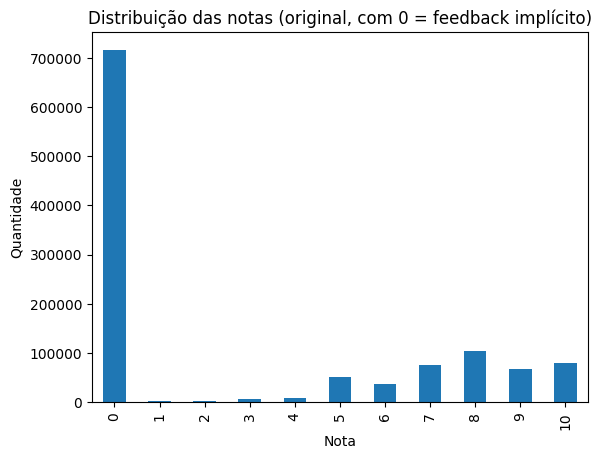

In [10]:
ratings_original['Book-Rating'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribuição das notas (original, com 0 = feedback implícito)')
plt.xlabel('Nota'); plt.ylabel('Quantidade')
plt.show()

como é possível ver no resultado do snippet acima, a incidencia da nota 0 é extremamente grande, mas isso se deve a forma como o dataset foi montado, nesse caso o zero não significa uma nota zero explicita, significa apenas que o usuario teve interação com o livro mas não o avaliou explicitamente.

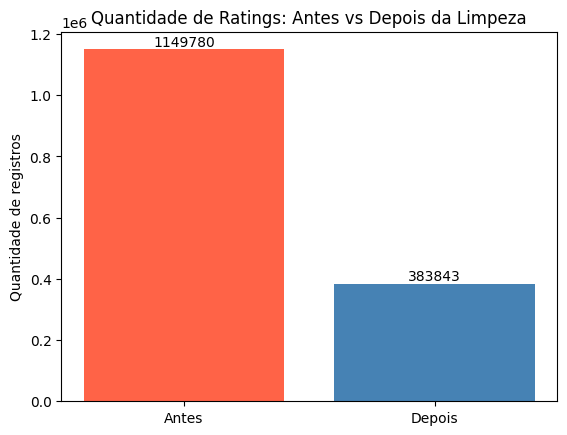

In [11]:
labels = ['Antes', 'Depois']
values = [ratings_original.shape[0], ratings.shape[0]]

plt.figure()
plt.bar(labels, values, color=['tomato', 'steelblue'])
plt.title('Quantidade de Ratings: Antes vs Depois da Limpeza')
plt.ylabel('Quantidade de registros')

for i, v in enumerate(values):
    plt.text(i, v + 10000, str(v), ha='center')

plt.show()

Quantidade de registros na tabela ratings antes (1.149.780) e depois (383.843) da limpeza, uma redução de 765.937 registros (cerca de 66,6%).

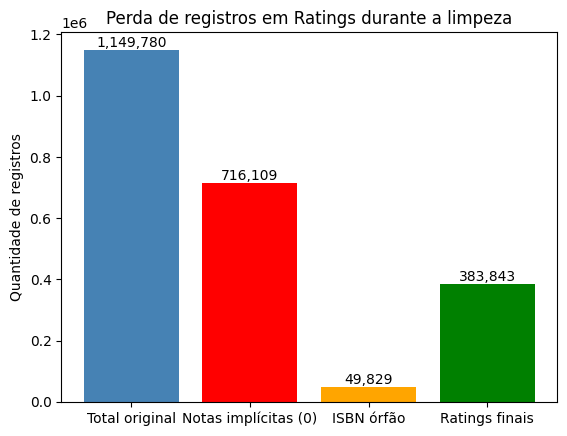

In [12]:
import matplotlib.pyplot as plt

# quantidade perdida em cada etapa
total_original = ratings_original.shape[0]
implicitos = (ratings_original['Book-Rating'] == 0).sum()
sem_implicitos = ratings_original[ratings_original['Book-Rating'] != 0]
orfaos = (~sem_implicitos['ISBN'].isin(books['ISBN'])).sum()
final = ratings.shape[0]

labels = ['Total original', 'Notas implícitas (0)', 'ISBN órfão', 'Ratings finais']
values = [total_original, implicitos, orfaos, final]
colors = ['steelblue', 'red', 'orange', 'green']

plt.figure()
bars = plt.bar(labels, values, color=colors)
plt.title('Perda de registros em Ratings durante a limpeza')
plt.ylabel('Quantidade de registros')

for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 10000, f'{v:,}', ha='center')

plt.show()

Registros removidos de ratings: 716.109 notas implícitas (nota 0) e 49.829 avaliações de ISBNs que não existem em books

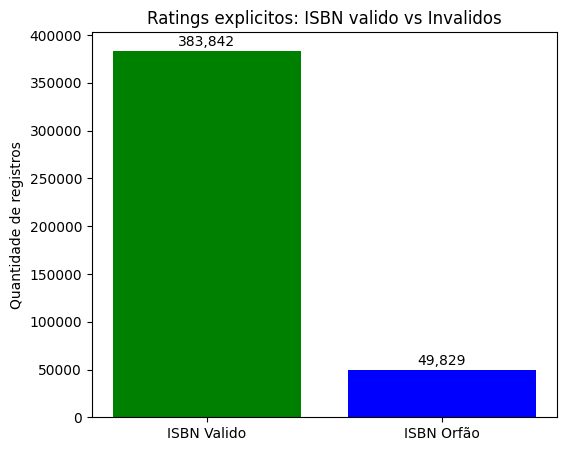

In [13]:
isbns_validos = sem_implicitos["ISBN"].isin(books["ISBN"]).sum()
isbns_invalidos = (~sem_implicitos["ISBN"].isin(books["ISBN"])).sum()

labels=["ISBN Valido" , "ISBN Orfão"]
values = [isbns_validos , isbns_invalidos]
colors = ["green" , "blue"]

plt.figure(figsize=(6, 5))
bars = plt.bar(labels,values, color=colors)
plt.title("Ratings explicitos: ISBN valido vs Invalidos")
plt.ylabel("Quantidade de registros")

for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 5000, f'{v:,}', ha='center')

plt.show()

Como a tabela de livros passou por uma limpeza (remoção de registros com data de publicação inválida), alguns ratings ficaram com ISBN órfão, pois os livros a que estavam associados foram removidos da tabela.

## Comportamento dos dados limpos (Seaborn)


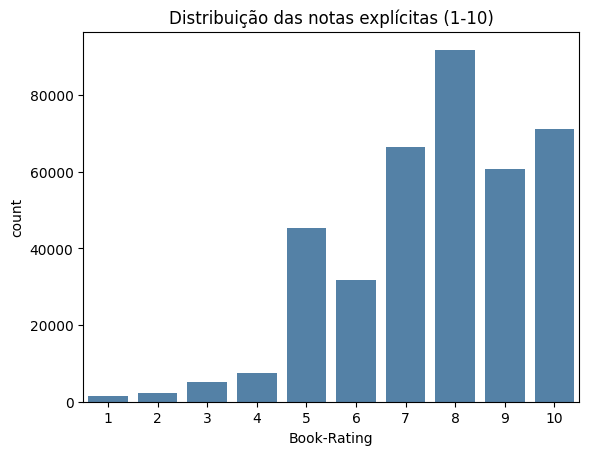

Média: 7.63
Mediana: 8.00


In [ ]:
sns.countplot(x='Book-Rating', data=ratings, color='steelblue')
plt.title('Distribuição das notas explícitas (1-10)')
plt.show()
print(f"Média: {ratings['Book-Rating'].mean():.2f}")
print(f"Mediana: {ratings['Book-Rating'].median():.2f}")

As notas explícitas se concentram nos valores altos: a média é 7,63 e a mediana é 8, sendo 8 a nota mais comum, seguida de 10, 7 e 9. Notas de 1 a 4 são raras. Isso indica um viés positivo, em que usuários tendem a avaliar bem os livros que escolheram ler. Há também um pico na nota 5, que pode ser usada como nota neutra.

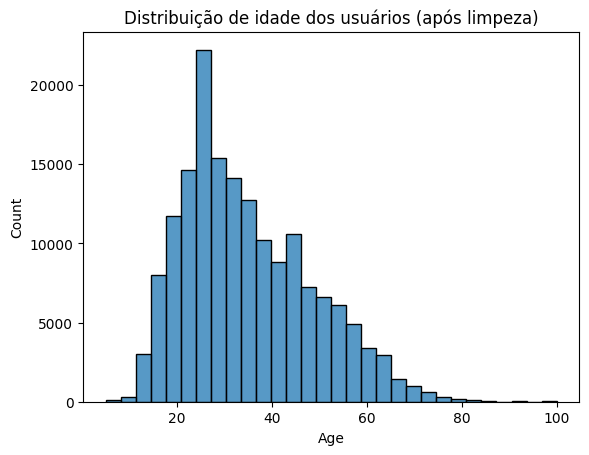

In [15]:
sns.histplot(users['Age'].dropna(), bins=30)
plt.title('Distribuição de idade dos usuários (após limpeza)')
plt.show()

A distribuição de idades é assimétrica à direita: a maior concentração de usuários está entre ~20 e ~35 anos, com pico por volta dos 25, e há uma cauda longa em direção às idades mais altas. Ou seja, o formato lembra um sino, mas não é simétrico.

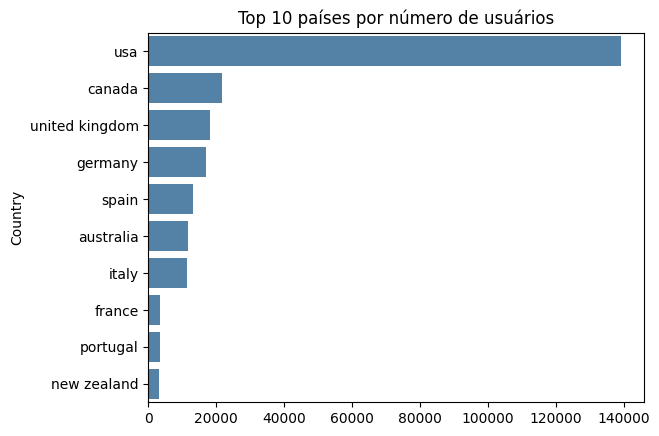

In [16]:
top = users['Country'].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title('Top 10 países por número de usuários')
plt.show()

Os EUA concentram a maior parte dos usuários, muito acima dos outros países. Isso acontece porque o dataset veio de uma comunidade online em inglês, então os resultados representam melhor esse público do que o resto do mundo.

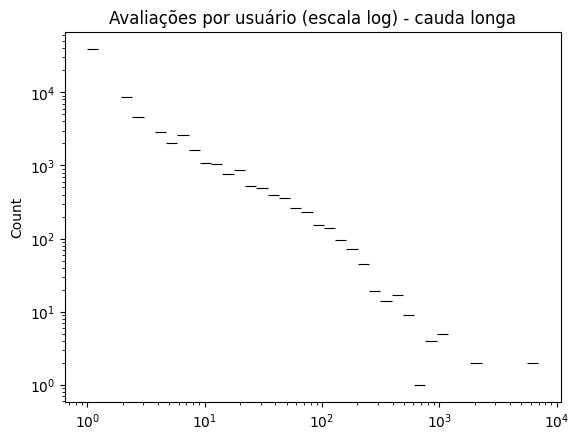

count    68091.000000
mean         5.637206
std         41.742519
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       6943.000000
dtype: float64
1.0


In [17]:
por_usuario = ratings.groupby('User-ID').size()
sns.histplot(por_usuario, log_scale=(True, True), bins=40)
plt.title('Avaliações por usuário (escala log) - cauda longa')
plt.show()
print(por_usuario.describe())
print(por_usuario.median())

A maioria dos usuários fez poucas avaliações: a mediana é 1, enquanto a média é ~5,6, puxada por uma minoria que fez centenas ou milhares. Isso forma uma cauda longa e indica que os dados são esparsos, o que dificulta a recomendação para usuários com pouco histórico.

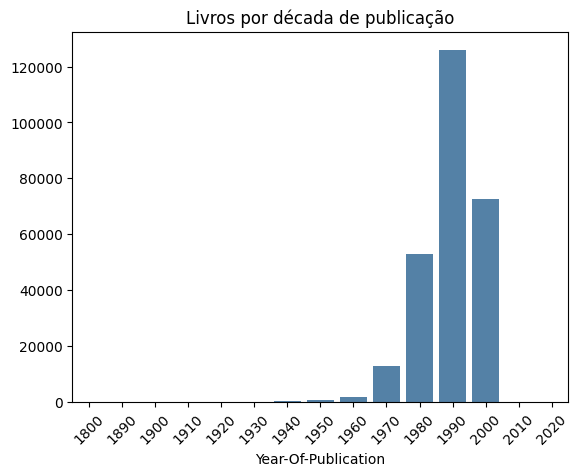

In [18]:
decada = (books['Year-Of-Publication'] // 10 * 10).dropna().astype(int).value_counts().sort_index()
decada = decada[decada.index >= 1800]
sns.barplot(x=decada.index.astype(str), y=decada.values, color='steelblue')
plt.xticks(rotation=45)
plt.title('Livros por década de publicação')
plt.show()

A maior parte dos livros foi publicada entre as décadas de 1980 e 2000, com pico nos anos 1990. Livros mais antigos são raros, o que indica que o catálogo reflete principalmente publicações recentes para a época da coleta do dataset.